# Decoding speech vs. non-speech from intracranial EEG
**ES 673 NeuroAI – Take-home assignment 5**

Dataset: OpenNeuro **ds003688** (Berezutskaya et al., 2022). One participant watched a short film whose
soundtrack alternates 30-s blocks of **speech** and **music** (= non-speech). The task is to decode,
from a short window of iEEG activity, whether the participant was hearing speech or not.

Pipeline
1. load the BrainVision recording + BIDS metadata with MNE
2. preprocess (notch filter, common-average reference)
3. extract log band-power envelopes (6 bands, 20 Hz)
4. align to the `events.tsv` labels and cut 1-s windows
5. train three decoders (logistic regression, 1-D CNN on the raw signal, LSTM on band-power sequences)
   with **leave-one-block-out** cross-validation
6. evaluate + visualise, 7. methodological explorations, 8. extra credit: acoustic vs. speech electrodes

In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy.ndimage import uniform_filter1d
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

mne.set_log_level('ERROR')
warnings.filterwarnings('ignore')

SUBJECT = 'sub-20'
DATA = Path('data/ds003688')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BANDS = {'delta': (1, 4), 'theta': (4, 8), 'alpha': (8, 13),
         'beta': (13, 30), 'gamma': (30, 70), 'hfb': (70, 170)}
ENV_FS = 16            # Hz, sampling rate of the band-power envelopes (512/16 = 32-sample bins of 62.5 ms)
WIN, STEP = 1.0, 0.5   # window length and stride, seconds
SEED = 0
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
print('device:', DEVICE)

device: cuda


## 1. Load the recording and its BIDS metadata with MNE
Channel types and bad channels are taken from `channels.tsv` (the BrainVision header calls everything "EEG").

In [2]:
ieeg = DATA / SUBJECT / 'ses-iemu' / 'ieeg'
stem = f'{SUBJECT}_ses-iemu_task-film'
raw = mne.io.read_raw_brainvision(ieeg / f'{stem}_acq-clinical_run-1_ieeg.vhdr', preload=True)
channels = pd.read_csv(ieeg / f'{stem}_acq-clinical_run-1_channels.tsv', sep='\t')
events = pd.read_csv(ieeg / f'{stem}_run-1_events.tsv', sep='\t')
electrodes = pd.read_csv(ieeg / f'{SUBJECT}_ses-iemu_acq-clinical_electrodes.tsv', sep='\t')

raw.set_channel_types({n: t.lower() if t.lower() in ('ecog', 'seeg', 'ecg', 'emg', 'eog') else 'misc'
                       for n, t in zip(channels.name, channels.type)})
raw.info['bads'] = channels.query("status == 'bad'").name.tolist()
n_bad = len(raw.info['bads'])
raw.pick(['ecog', 'seeg'], exclude='bads')
FS = int(raw.info['sfreq'])
print(raw)
print(f'{len(raw.ch_names)} good iEEG channels, {raw.times[-1]:.1f} s at {FS} Hz, {n_bad} bad channels dropped')
events

<RawBrainVision | sub-20_ses-iemu_task-film_acq-clinical_run-1_ieeg.eeg, 88 x 200605 (391.8 s), ~134.8 MiB, data loaded>
88 good iEEG channels, 391.8 s at 512 Hz, 8 bad channels dropped


,onset,duration,trial_type,value
0,0.898,0.020,start task,9
1,0.918,29.992,music,2
2,30.910,30.000,speech,1
3,60.910,30.000,music,2
4,90.910,30.000,speech,1
5,120.910,30.004,music,2
6,150.914,29.996,speech,1
7,180.910,30.000,music,2
8,210.910,30.000,speech,1
9,240.910,30.000,music,2


`events.tsv` gives 13 alternating blocks (7 music, 6 speech) of 30 s each. Film time 0 = `start task`.

In [3]:
blocks = events[events.trial_type.isin(['music', 'speech'])].reset_index(drop=True)
blocks['y'] = (blocks.trial_type == 'speech').astype(int)        # 1 = speech, 0 = music (non-speech)
t_start = events.query("trial_type == 'start task'").onset.item()
t_end = events.query("trial_type == 'end task'").onset.item()


def shade_blocks(ax):
    """Shade speech (orange) and music (blue) blocks on a time axis."""
    for _, b in blocks.iterrows():
        ax.axvspan(b.onset, b.onset + b.duration, color='tab:orange' if b.y else 'tab:blue', alpha=.15, lw=0)


print(blocks.groupby('trial_type').duration.agg(['count', 'sum']))

            count      sum
trial_type                
music           7  210.021
speech          6  180.000


## 2. Preprocessing
* notch filter at 50 Hz and harmonics (European mains)
* common-average reference (CAR) over the good iEEG channels, to remove signal shared by all electrodes

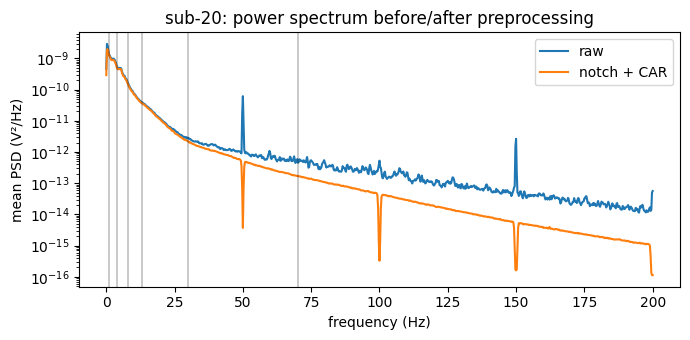

In [4]:
psd_before = raw.compute_psd(fmax=200)
raw.notch_filter(np.arange(50, 201, 50))
raw.set_eeg_reference('average')
psd_after = raw.compute_psd(fmax=200)

fig, ax = plt.subplots(figsize=(7, 3.5))
for psd, label in [(psd_before, 'raw'), (psd_after, 'notch + CAR')]:
    ax.semilogy(psd.freqs, psd.get_data().mean(0), label=label)
for lo, hi in BANDS.values():
    ax.axvline(lo, color='k', lw=.3)
ax.set(xlabel='frequency (Hz)', ylabel='mean PSD (V²/Hz)', title=f'{SUBJECT}: power spectrum before/after preprocessing')
ax.legend(); fig.tight_layout(); fig.savefig(FIG / 'fig1_psd.png', dpi=150)

## 3. Feature extraction: log band-power envelopes
For every channel and frequency band: band-pass filter → Hilbert amplitude → log → average into 62.5-ms bins.
The result is a (channels × time × bands) array at 16 Hz. This single array gives us
* **spectral features**: the mean over a window (log band power), used by logistic regression;
* **temporal features**: the 16-step sequence inside a window, used by the LSTM.
The CNN works directly on the preprocessed raw signal instead.

In [5]:
def band_envelopes(raw, bands, fs_out):
    step = int(round(raw.info['sfreq'] / fs_out))
    assert step * fs_out == raw.info['sfreq'], 'fs_out must divide the sampling rate exactly'
    out = []
    for lo, hi in bands.values():
        env = raw.copy().filter(lo, hi).apply_hilbert(envelope=True).get_data()
        n = env.shape[1] // step
        out.append(np.log(env[:, :n * step]).reshape(env.shape[0], n, step).mean(2))
    return np.stack(out, -1).astype(np.float32)        # (n_ch, n_time, n_band)


t0 = time.time()
env = band_envelopes(raw, BANDS, ENV_FS)
env_t = np.arange(env.shape[1]) / ENV_FS               # bin start times in seconds
print(env.shape, f'({time.time() - t0:.0f} s)')

(88, 6268, 6) (8 s)


Quick look at the alignment: high-frequency-band (HFB, 70–170 Hz) power of every channel over the film.

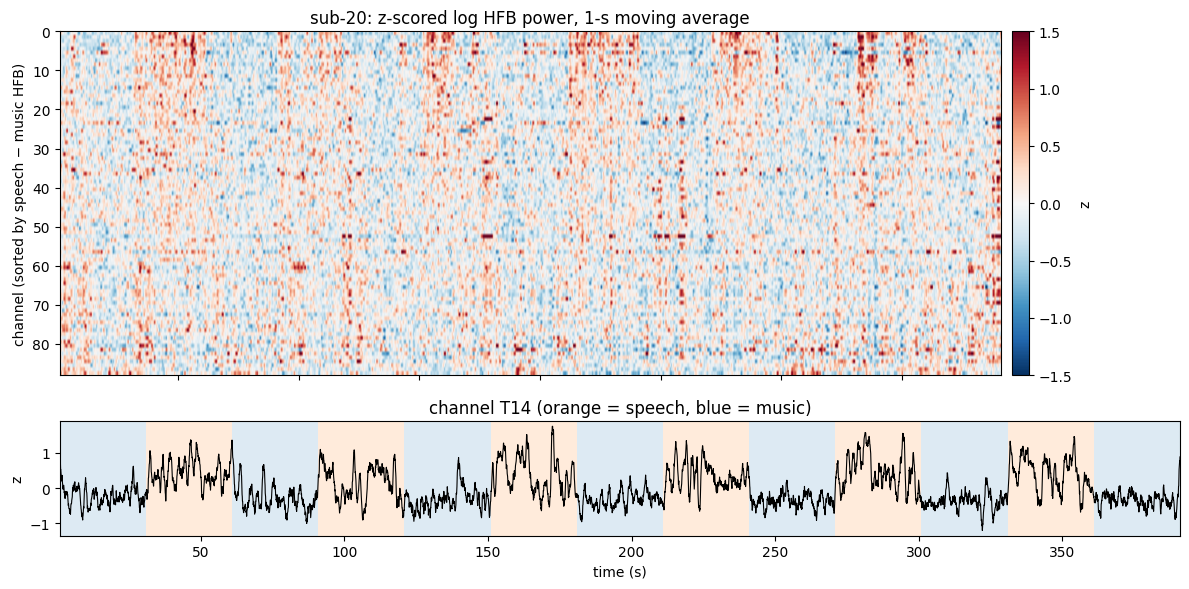

In [6]:
hfb_i = list(BANDS).index('hfb')
hfb = env[:, :, hfb_i]
hfb_z = (hfb - hfb.mean(1, keepdims=True)) / hfb.std(1, keepdims=True)
hfb_s = uniform_filter1d(hfb_z, ENV_FS, axis=1)                                 # 1-s moving average, for display only
in_film = (env_t >= t_start) & (env_t < t_end)
block_mean = np.stack([hfb[:, (env_t >= b.onset) & (env_t < b.onset + b.duration)].mean(1)
                       for _, b in blocks.iterrows()], 1)                       # (n_ch, n_block)
contrast = block_mean[:, blocks.y == 1].mean(1) - block_mean[:, blocks.y == 0].mean(1)
order = np.argsort(-contrast)
top = order[0]

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
im = ax[0].imshow(hfb_s[order][:, in_film], aspect='auto', cmap='RdBu_r', vmin=-1.5, vmax=1.5,
                  extent=[t_start, t_end, len(order), 0])
ax[0].set(ylabel='channel (sorted by speech − music HFB)', title=f'{SUBJECT}: z-scored log HFB power, 1-s moving average')
plt.colorbar(im, ax=ax[0], pad=.01, label='z')
ax[1].plot(env_t[in_film], hfb_s[top][in_film], color='k', lw=.8)
shade_blocks(ax[1])
ax[1].set(xlabel='time (s)', ylabel='z', title=f'channel {raw.ch_names[top]} (orange = speech, blue = music)')
fig.tight_layout(); fig.savefig(FIG / 'fig2_hfb_alignment.png', dpi=150)

## 4. Align with the labels and cut windows
Each 30-s block is cut into 1-s windows with 0.5-s stride. Every window keeps its label and its block id;
the block id is what we split on later.

In [7]:
def make_windows(win=WIN, step=STEP):
    rows = [(t, b.y, i) for i, b in blocks.iterrows()
            for t in np.arange(b.onset, b.onset + b.duration - win + 1e-6, step)]
    return pd.DataFrame(rows, columns=['t', 'y', 'block'])


def cut(arr, fs, starts, win):
    """arr: (n_ch, n_time, ...) → (n_win, n_ch, win*fs, ...)"""
    n = int(round(win * fs))
    return np.stack([arr[:, int(round(s * fs)):int(round(s * fs)) + n] for s in starts])


win_df = make_windows()
y, groups = win_df.y.values, win_df.block.values
X_env = cut(env, ENV_FS, win_df.t, WIN)                                        # (n_win, n_ch, 16, n_band)
X_feat = X_env.mean(2).reshape(len(win_df), -1)                                # (n_win, n_ch*n_band)
X_seq = X_env.transpose(0, 2, 1, 3).reshape(len(win_df), X_env.shape[2], -1)   # (n_win, 16, n_ch*n_band)
X_raw = cut(raw.get_data() * 1e6, FS, win_df.t, WIN).astype(np.float32)       # (n_win, n_ch, 512) in µV
print('windows:', len(win_df), '| speech:', y.sum(), '| music:', (y == 0).sum())
print('X_feat', X_feat.shape, '| X_seq', X_seq.shape, '| X_raw', X_raw.shape)

windows: 763 | speech: 352 | music: 411
X_feat (763, 528) | X_seq (763, 16, 528) | X_raw (763, 88, 512)


## 5. Decoders and block-wise cross-validation
Neighbouring windows inside one block are nearly identical, so a random train/test split of windows would
leak the test set into training. We therefore use **leave-one-block-out (LOBO)** cross-validation: each of
the 13 blocks is held out once and the model is trained on the other 12 (always containing both classes).
Every window is thus predicted by a model that never saw its block, and the predictions are pooled.

Three decoders:
* **LogReg** – logistic regression on log band power (channels × 6 bands),
* **CNN** – 1-D temporal convolutions over the raw multichannel signal (channels = input channels),
* **LSTM** – recurrent network over the 16-step sequence of band-power vectors.

In [8]:
def lobo_cv(fit_predict, X, y, groups):
    """Out-of-fold P(speech) for every window, leaving one block out at a time."""
    prob = np.zeros(len(y))
    for b in np.unique(groups):
        tr, te = groups != b, groups == b
        prob[te] = fit_predict(X[tr], y[tr], X[te])
    return prob


def fit_logreg(Xtr, ytr, Xte, C=0.1):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)).fit(Xtr, ytr)
    return m.predict_proba(Xte)[:, 1]


class CNN(nn.Module):
    """(B, n_ch, T) → logit"""
    def __init__(self, n_ch, n_filt=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_ch, n_filt, 15, padding=7), nn.BatchNorm1d(n_filt), nn.ReLU(), nn.MaxPool1d(4),
            nn.Conv1d(n_filt, n_filt, 15, padding=7), nn.BatchNorm1d(n_filt), nn.ReLU(), nn.MaxPool1d(4),
            nn.Conv1d(n_filt, n_filt, 7, padding=3), nn.BatchNorm1d(n_filt), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(n_filt, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


class LSTM(nn.Module):
    """(B, T, n_feat) → logit"""
    def __init__(self, n_feat, n_hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, n_hidden, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(0.5), nn.Linear(n_hidden, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)


def fit_torch(make_model, Xtr, ytr, Xte, norm_axes, epochs=30, lr=1e-3, wd=1e-2, batch=64):
    """Standardise with training statistics, train with AdamW + BCE, return P(speech) on Xte."""
    mu, sd = Xtr.mean(norm_axes, keepdims=True), Xtr.std(norm_axes, keepdims=True) + 1e-6
    Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    torch.manual_seed(SEED)
    model = make_model().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.BCEWithLogitsLoss()
    Xt = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(ytr, dtype=torch.float32, device=DEVICE)
    for _ in range(epochs):
        model.train()
        for idx in torch.randperm(len(Xt), device=DEVICE).split(batch):
            opt.zero_grad()
            loss_fn(model(Xt[idx]), yt[idx]).backward()
            opt.step()
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(Xte, dtype=torch.float32, device=DEVICE))).cpu().numpy()


def fit_cnn(Xtr, ytr, Xte):
    return fit_torch(lambda: CNN(Xtr.shape[1]), Xtr, ytr, Xte, norm_axes=(0, 2))


def fit_lstm(Xtr, ytr, Xte):
    return fit_torch(lambda: LSTM(Xtr.shape[2]), Xtr, ytr, Xte, norm_axes=(0, 1))


runs = {'LogReg (band power)': (fit_logreg, X_feat),
        'CNN (raw signal)': (fit_cnn, X_raw),
        'LSTM (band-power sequence)': (fit_lstm, X_seq)}
probs = {}
for name, (fit, X) in runs.items():
    t0 = time.time()
    probs[name] = lobo_cv(fit, X, y, groups)
    print(f'{name:28s} done in {time.time() - t0:5.0f} s')

LogReg (band power)          done in     0 s


CNN (raw signal)             done in    33 s


LSTM (band-power sequence)   done in    21 s


## 6. Evaluation and visualisation

In [9]:
def metrics(y, p):
    yhat = (p > 0.5).astype(int)
    return dict(accuracy=accuracy_score(y, yhat), balanced_accuracy=balanced_accuracy_score(y, yhat),
                f1=f1_score(y, yhat), roc_auc=roc_auc_score(y, p))


results = pd.DataFrame({k: metrics(y, p) for k, p in probs.items()}).T
results.round(3)

,accuracy,balanced_accuracy,f1,roc_auc
LogReg (band power),0.858,0.857,0.844,0.917
CNN (raw signal),0.822,0.821,0.807,0.903
LSTM (band-power sequence),0.823,0.823,0.810,0.858


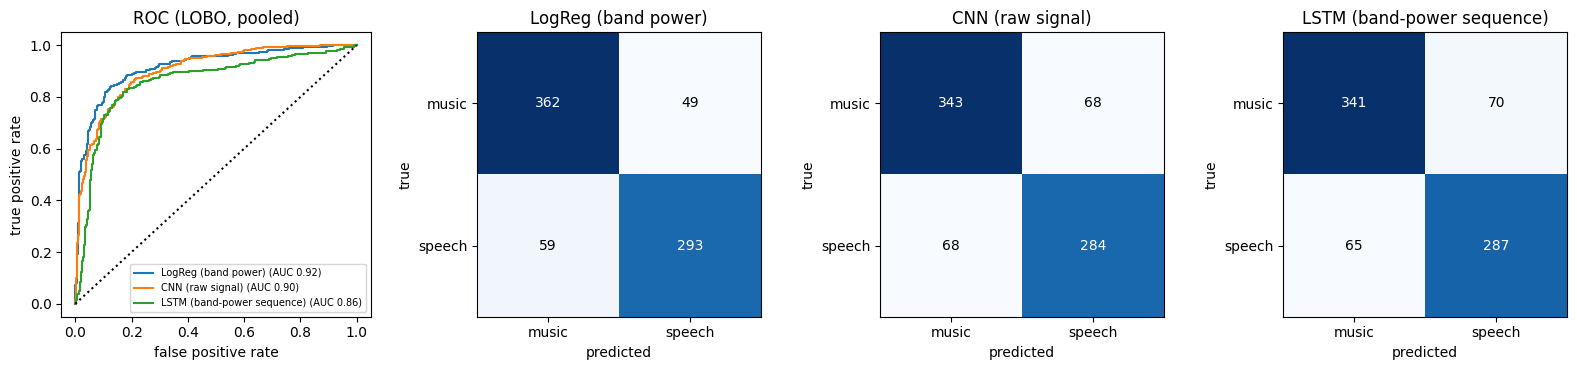

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for name, p in probs.items():                                   # ROC curves
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y, p):.2f})')
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set(xlabel='false positive rate', ylabel='true positive rate', title='ROC (LOBO, pooled)')
ax[0].legend(fontsize=7)
for a, (name, p) in zip(ax[1:], probs.items()):                 # confusion matrices
    cm = confusion_matrix(y, p > 0.5)
    a.imshow(cm, cmap='Blues'); a.set(title=name, xticks=[0, 1], yticks=[0, 1], xticklabels=['music', 'speech'],
                                      yticklabels=['music', 'speech'], xlabel='predicted', ylabel='true')
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha='center', va='center', color='w' if cm[i, j] > cm.max() / 2 else 'k')
fig.tight_layout(); fig.savefig(FIG / 'fig3_roc_confusion.png', dpi=150)

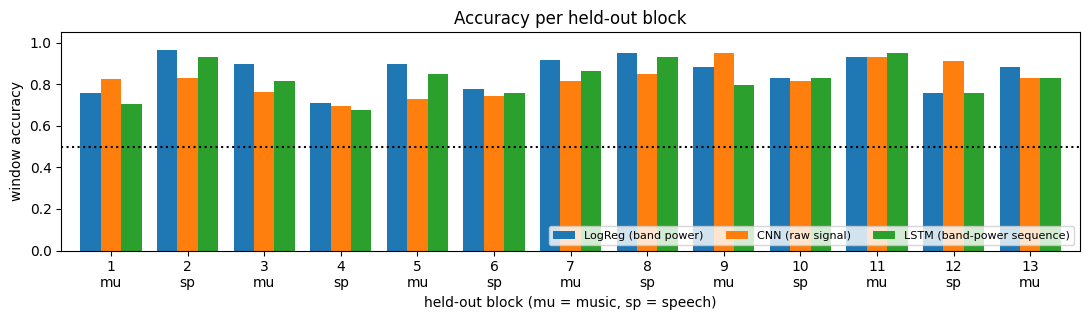

In [11]:
per_block = pd.DataFrame({name: [((p[groups == b] > 0.5) == y[groups == b]).mean() for b in range(len(blocks))]
                          for name, p in probs.items()})
per_block.index = [f'{i + 1}\n{t[:2]}' for i, t in enumerate(blocks.trial_type)]
ax = per_block.plot.bar(figsize=(11, 3.3), width=.8, rot=0)
ax.axhline(0.5, color='k', ls=':'); ax.set(ylabel='window accuracy', xlabel='held-out block (mu = music, sp = speech)',
                                           title='Accuracy per held-out block', ylim=(0, 1.05))
ax.legend(fontsize=8, ncol=3, loc='lower right')
plt.tight_layout(); plt.savefig(FIG / 'fig4_per_block.png', dpi=150)

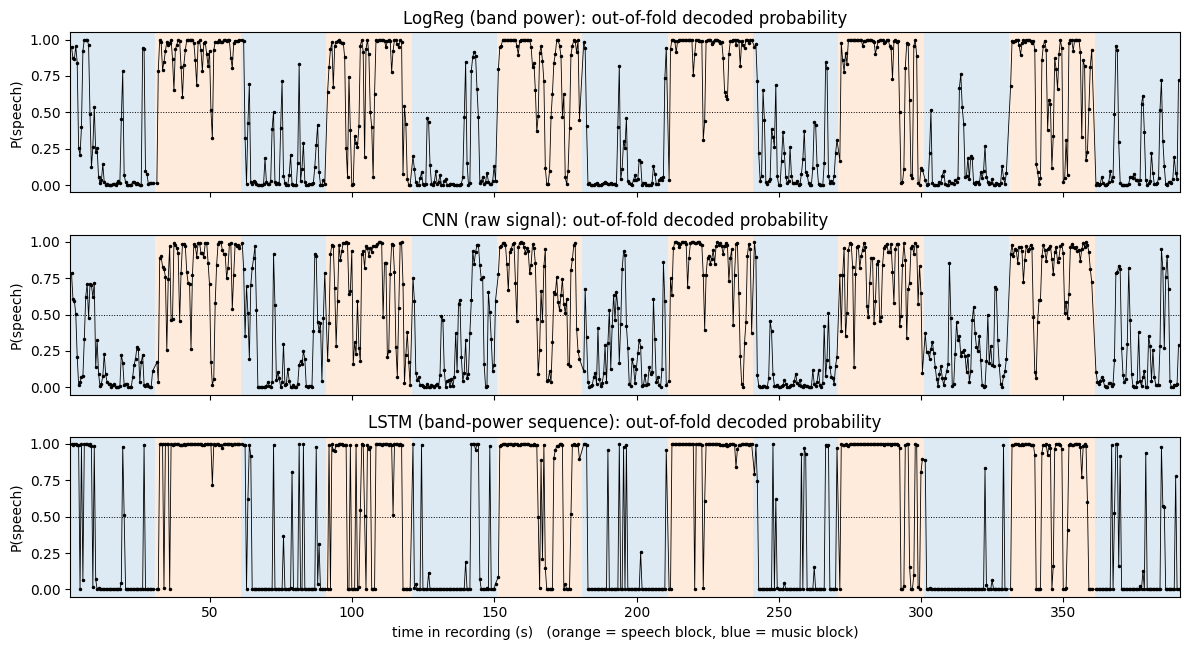

In [12]:
fig, ax = plt.subplots(len(probs), 1, figsize=(12, 2.2 * len(probs)), sharex=True)
for a, (name, p) in zip(ax, probs.items()):
    a.plot(win_df.t + WIN / 2, p, '.-', ms=3, lw=.6, color='k')
    a.axhline(0.5, color='k', ls=':', lw=.7); shade_blocks(a)
    a.set(ylabel='P(speech)', ylim=(-.05, 1.05), title=f'{name}: out-of-fold decoded probability', xlim=(t_start, t_end))
ax[-1].set(xlabel='time in recording (s)   (orange = speech block, blue = music block)')
fig.tight_layout(); fig.savefig(FIG / 'fig5_timeline.png', dpi=150)

## 7. Methodological explorations
### 7a. Random window split vs. block-wise split
The same logistic regression evaluated with a shuffled 5-fold split of *windows*.

In [13]:
def random_cv(fit_predict, X, y, k=5):
    prob = np.zeros(len(y))
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=SEED).split(X, y):
        prob[te] = fit_predict(X[tr], y[tr], X[te])
    return prob


explore = {}
explore['split'] = pd.DataFrame({'random window split': metrics(y, random_cv(fit_logreg, X_feat, y)),
                                 'leave-one-block-out': metrics(y, probs['LogReg (band power)'])}).T
explore['split'].round(3)

,accuracy,balanced_accuracy,f1,roc_auc
random window split,0.937,0.936,0.931,0.985
leave-one-block-out,0.858,0.857,0.844,0.917


### 7b. Which frequency bands carry the information? (single-band logistic regression, LOBO)

In [14]:
band_acc = {b: metrics(y, lobo_cv(fit_logreg, X_env[:, :, :, i].mean(2), y, groups))
            for i, b in enumerate(BANDS)}
band_acc['all bands'] = metrics(y, probs['LogReg (band power)'])
explore['bands'] = pd.DataFrame(band_acc).T
explore['bands'].round(3)

,accuracy,balanced_accuracy,f1,roc_auc
delta,0.739,0.735,0.709,0.815
theta,0.813,0.811,0.797,0.896
alpha,0.759,0.757,0.738,0.835
beta,0.718,0.717,0.698,0.761
gamma,0.763,0.760,0.740,0.841
hfb,0.835,0.832,0.817,0.891
all bands,0.858,0.857,0.844,0.917


### 7c. Window length (logistic regression on all bands, LOBO)

In [15]:
win_acc = {}
for w in [0.5, 1.0, 2.0, 4.0]:
    d = make_windows(w, w / 2)
    Xw = cut(env, ENV_FS, d.t, w).mean(2).reshape(len(d), -1)
    win_acc[f'{w} s'] = metrics(d.y.values, lobo_cv(fit_logreg, Xw, d.y.values, d.block.values))
explore['window'] = pd.DataFrame(win_acc).T
explore['window'].round(3)

,accuracy,balanced_accuracy,f1,roc_auc
0.5 s,0.804,0.803,0.788,0.866
1.0 s,0.858,0.857,0.844,0.917
2.0 s,0.887,0.885,0.875,0.945
4.0 s,0.910,0.908,0.900,0.975


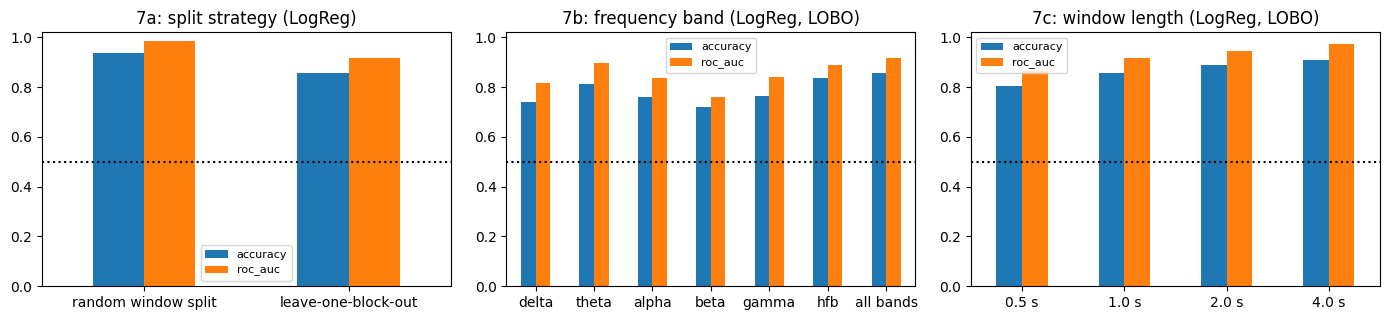

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
explore['split'][['accuracy', 'roc_auc']].plot.bar(ax=ax[0], rot=0, title='7a: split strategy (LogReg)')
explore['bands'][['accuracy', 'roc_auc']].plot.bar(ax=ax[1], rot=0, title='7b: frequency band (LogReg, LOBO)')
explore['window'][['accuracy', 'roc_auc']].plot.bar(ax=ax[2], rot=0, title='7c: window length (LogReg, LOBO)')
for a in ax:
    a.axhline(0.5, color='k', ls=':'); a.set_ylim(0, 1.02); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig6_explorations.png', dpi=150)

## 8. Extra credit: acoustic vs. speech-specific responses across electrodes
Two indices per electrode, both computed from log-HFB power:
* **speech selectivity** – Cohen's d of the 1-s window power, speech vs. music blocks
  (positive = prefers speech, negative = prefers music);
* **acoustic-onset response** – transient HFB increase 0.05–0.35 s after a *sentence onset*
  (`stimuli/annotations/sound/sound_annotation_sentences.tsv`) relative to the 0.5 s before it,
  as a paired Cohen's d over sentence onsets. Sentence onsets are sharp acoustic edges, so this index
  captures stimulus-locked acoustic processing rather than a sustained preference for speech.

Electrodes are drawn at their ACPC coordinates from `electrodes.tsv` (sagittal view, left hemisphere).

In [17]:
def cohen_d(a, b):
    return (a.mean(0) - b.mean(0)) / np.sqrt(0.5 * (a.var(0) + b.var(0)))


H = X_env[:, :, :, hfb_i].mean(2)                                   # (n_win, n_ch) log HFB power per window
sent = pd.read_csv(DATA / 'stimuli/annotations/sound/sound_annotation_sentences.tsv', sep='\t')
onsets = sent.onset.values + t_start                                # film time → recording time
pre, post = 0.5, 1.5
i0 = np.round((onsets - pre) * ENV_FS).astype(int)
epochs = np.stack([hfb[:, i:i + int((pre + post) * ENV_FS)] for i in i0])          # (n_sent, n_ch, n_t)
epochs -= epochs[:, :, :int(pre * ENV_FS)].mean(2, keepdims=True)                   # subtract pre-onset baseline
erp_t = np.arange(epochs.shape[2]) / ENV_FS - pre
resp = epochs[:, :, (erp_t >= 0.05) & (erp_t < 0.35)].mean(2)                      # (n_sent, n_ch)

elec = electrodes.set_index('name').loc[raw.ch_names, ['x', 'y', 'z']].astype(float)
elec['group'] = channels.set_index('name').loc[raw.ch_names, 'group'].values
elec['d_speech'] = cohen_d(H[y == 1], H[y == 0])
elec['d_onset'] = resp.mean(0) / resp.std(0)
print(f'{len(sent)} sentence onsets')
elec.groupby('group')[['d_speech', 'd_onset']].agg(['mean', 'max', 'count']).round(2)

67 sentence onsets


d_speech             d_onset            
          mean   max count    mean   max count
group                                         
F         0.19  0.71     8   -0.04  0.15     8
Oc        0.14  0.87     8    0.06  0.26     8
P         0.20  0.80    14    0.09  0.44    14
PO        0.03  0.43    16    0.04  0.33    16
T         0.60  1.85    32    0.06  0.70    32
sT        0.22  0.49     5   -0.12  0.05     5
vT        0.38  0.62     5   -0.07  0.12     5

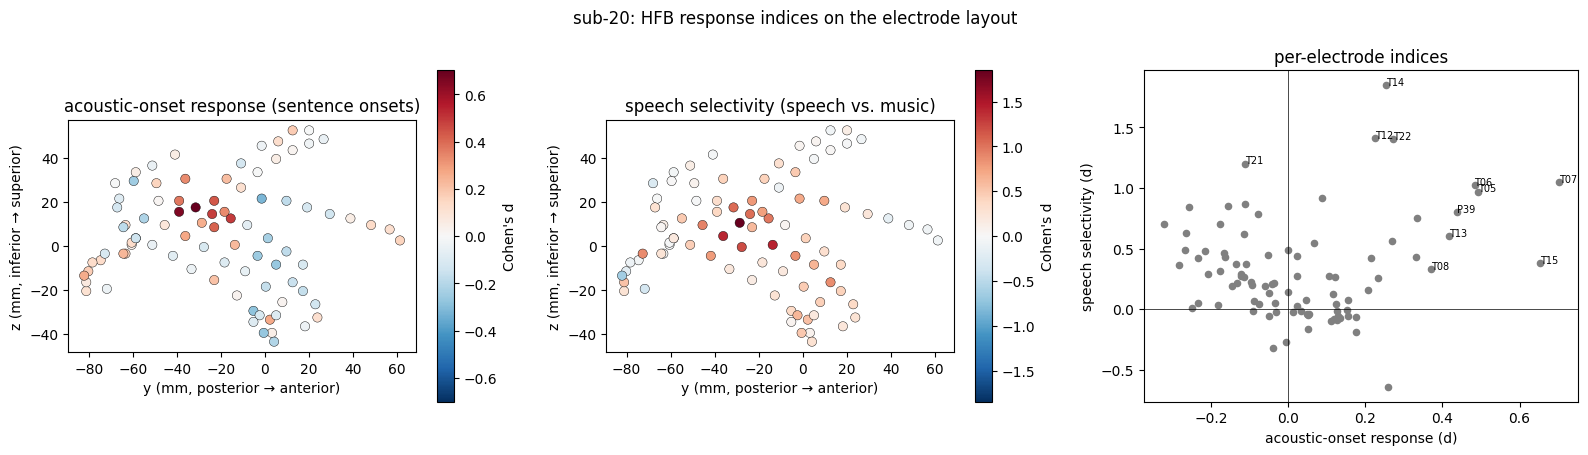

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, col, title in zip(ax, ['d_onset', 'd_speech'], ['acoustic-onset response (sentence onsets)',
                                                        'speech selectivity (speech vs. music)']):
    v = np.abs(elec[col]).max()
    sc = a.scatter(elec.y, elec.z, c=elec[col], cmap='RdBu_r', vmin=-v, vmax=v, s=45, edgecolor='k', lw=.3)
    a.set(xlabel='y (mm, posterior → anterior)', ylabel='z (mm, inferior → superior)', title=title); a.set_aspect('equal')
    plt.colorbar(sc, ax=a, label="Cohen's d")
ax[2].scatter(elec.d_onset, elec.d_speech, s=20, color='gray')
for n, r in elec.iterrows():
    if abs(r.d_speech) > np.percentile(np.abs(elec.d_speech), 92) or r.d_onset > np.percentile(elec.d_onset, 92):
        ax[2].annotate(n, (r.d_onset, r.d_speech), fontsize=7)
ax[2].axhline(0, color='k', lw=.5); ax[2].axvline(0, color='k', lw=.5)
ax[2].set(xlabel='acoustic-onset response (d)', ylabel='speech selectivity (d)', title='per-electrode indices')
fig.suptitle(f'{SUBJECT}: HFB response indices on the electrode layout')
fig.tight_layout(); fig.savefig(FIG / 'fig7_electrode_maps.png', dpi=150)

Time-locked view: HFB around sentence onsets for the electrodes with the strongest onset response and
the strongest speech selectivity.

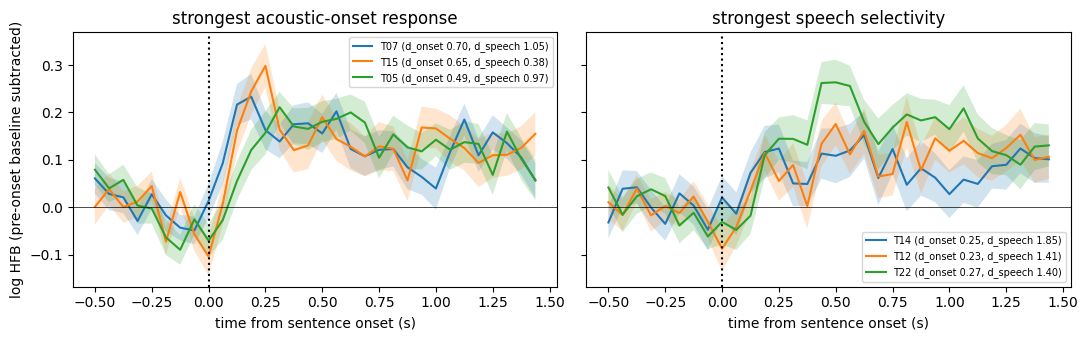

In [19]:
top_onset = elec.d_onset.sort_values(ascending=False).index[:3]
top_speech = elec.d_speech.sort_values(ascending=False).index[:3]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, names, title in zip(ax, [top_onset, top_speech], ['strongest acoustic-onset response', 'strongest speech selectivity']):
    for n in names:
        e = epochs[:, raw.ch_names.index(n)]
        m, se = e.mean(0), e.std(0) / np.sqrt(len(e))
        a.plot(erp_t, m, label=f'{n} (d_onset {elec.d_onset[n]:.2f}, d_speech {elec.d_speech[n]:.2f})')
        a.fill_between(erp_t, m - se, m + se, alpha=.2)
    a.axvline(0, color='k', ls=':'); a.axhline(0, color='k', lw=.5)
    a.set(xlabel='time from sentence onset (s)', title=f'{title}'); a.legend(fontsize=7)
ax[0].set_ylabel('log HFB (pre-onset baseline subtracted)')
fig.tight_layout(); fig.savefig(FIG / 'fig8_sentence_onset.png', dpi=150)

## 9. Save results

In [20]:
results.to_csv('results.csv')
elec.round(3).to_csv('electrode_indices.csv')
json.dump({'subject': SUBJECT, 'n_channels': len(raw.ch_names), 'n_windows': int(len(y)),
           'models': results.round(4).to_dict('index'),
           'explorations': {k: v.round(4).to_dict('index') for k, v in explore.items()}},
          open('results.json', 'w'), indent=1)
results.round(3)

,accuracy,balanced_accuracy,f1,roc_auc
LogReg (band power),0.858,0.857,0.844,0.917
CNN (raw signal),0.822,0.821,0.807,0.903
LSTM (band-power sequence),0.823,0.823,0.810,0.858
